Loading generation_data.csv...
Original dataset: (2557, 15)
After feature engineering: (2551, 31)

Features used by XGBoost/LSTM:
  - ALLSKY_SFC_SW_DWN
  - CLRSKY_SFC_SW_DWN
  - WS10M
  - WS50M
  - T2M
  - RH2M
  - PRECTOTCORR
  - wind_power_mw
  - total_energy_mwh
  - day_of_year
  - month
  - year
  - day_of_week
  - dayofyear
  - dayofweek
  - doy_sin
  - doy_cos
  - ALLSKY_SFC_SW_DWN_lag1
  - ALLSKY_SFC_SW_DWN_roll7
  - T2M_lag1
  - T2M_roll7
  - WS10M_lag1
  - WS10M_roll7
  - WS50M_lag1
  - WS50M_roll7
  - RH2M_lag1
  - RH2M_roll7
  - PRECTOTCORR_lag1
  - PRECTOTCORR_roll7

TRAIN / TEST SPLIT
Training rows: 2371
Testing rows:  180
Training period: 2018-01-07 to 2024-07-04
Testing period: 2024-07-05 to 2024-12-31


FORECASTING: solar_energy_mwh

Training Prophet...


12:07:05 - cmdstanpy - INFO - Chain [1] start processing
12:07:05 - cmdstanpy - INFO - Chain [1] done processing


Training XGBoost...
Training LSTM...


C:\Users\91798\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
12:07:49 - cmdstanpy - INFO - Chain [1] start processing




FORECASTING: wind_energy_mwh

Training Prophet...


12:07:49 - cmdstanpy - INFO - Chain [1] done processing


Training XGBoost...
Training LSTM...


C:\Users\91798\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)




MODEL COMPARISON
  model           target       RMSE        MAE      MAPE_%       R2
XGBoost solar_energy_mwh   3.152469   2.083332    1.659830 0.997903
   LSTM solar_energy_mwh  38.551968  28.028008   23.818187 0.686405
Prophet solar_energy_mwh  42.004102  31.910614   27.083376 0.627729
XGBoost  wind_energy_mwh   2.082581   0.999580    2.394525 0.999857
Prophet  wind_energy_mwh 167.213157 111.727315 1609.897519 0.079552
   LSTM  wind_energy_mwh 169.366166 118.644041 1587.027764 0.055696


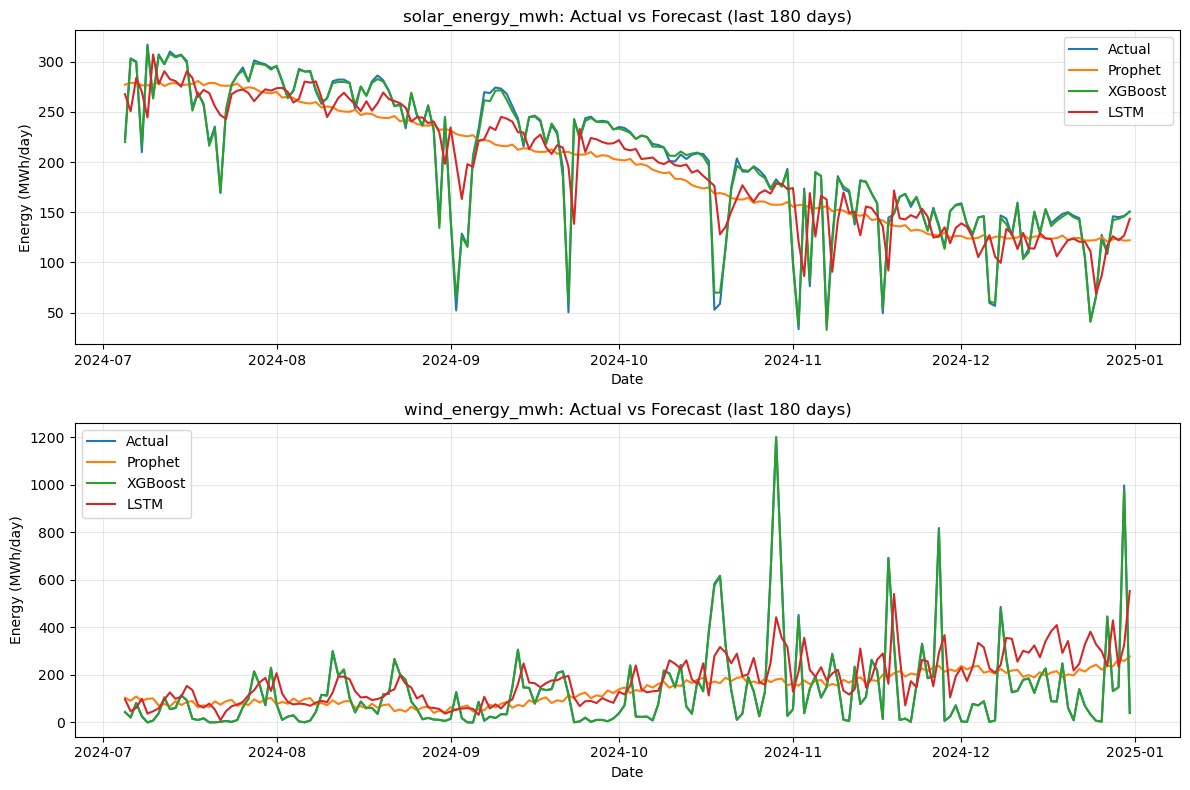


FILES CREATED
1. model_comparison.csv
2. forecast_comparison.png


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from sklearn.preprocessing import MinMaxScaler


TARGETS = [
    "solar_energy_mwh",
    "wind_energy_mwh"
]

TEST_DAYS = 180
LOOKBACK = 14


def build_features(df):

    df = df.copy()

    df["dayofyear"] = df.index.dayofyear
    df["month"] = df.index.month
    df["dayofweek"] = df.index.dayofweek

    df["doy_sin"] = np.sin(
        2 * np.pi * df["dayofyear"] / 365.25
    )

    df["doy_cos"] = np.cos(
        2 * np.pi * df["dayofyear"] / 365.25
    )

    weather_columns = [
        "ALLSKY_SFC_SW_DWN",
        "T2M",
        "WS10M",
        "WS50M",
        "RH2M",
        "PRECTOTCORR"
    ]

    for col in weather_columns:

        if col in df.columns:

            df[f"{col}_lag1"] = df[col].shift(1)

            df[f"{col}_roll7"] = (
                df[col]
                .rolling(
                    window=7,
                    min_periods=7
                )
                .mean()
            )

    return df.dropna()


def evaluate(y_true, y_pred, model_name, target):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    non_zero = y_true != 0

    if np.any(non_zero):

        mape = np.mean(
            np.abs(
                (y_true[non_zero] - y_pred[non_zero])
                / y_true[non_zero]
            )
        ) * 100

    else:

        mape = np.nan

    r2 = r2_score(
        y_true,
        y_pred
    )

    return {
        "model": model_name,
        "target": target,
        "RMSE": rmse,
        "MAE": mae,
        "MAPE_%": mape,
        "R2": r2
    }


def run_prophet(target, train, test):

    from prophet import Prophet

    prophet_train = (
        train
        .reset_index()[["date", target]]
        .rename(
            columns={
                "date": "ds",
                target: "y"
            }
        )
    )

    model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=True,
        daily_seasonality=False
    )

    model.fit(prophet_train)

    future = (
        test
        .reset_index()[["date"]]
        .rename(
            columns={
                "date": "ds"
            }
        )
    )

    forecast = model.predict(future)

    predictions = forecast["yhat"].values

    return np.clip(
        predictions,
        0,
        None
    )


def run_xgboost(
    target,
    train,
    test,
    feature_cols
):

    from xgboost import XGBRegressor

    model = XGBRegressor(
        n_estimators=400,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        objective="reg:squarederror"
    )

    model.fit(
        train[feature_cols],
        train[target]
    )

    predictions = model.predict(
        test[feature_cols]
    )

    return np.clip(
        predictions,
        0,
        None
    )


def run_lstm(
    target,
    train,
    test,
    feature_cols,
    lookback=14
):

    import tensorflow as tf

    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import (
        LSTM,
        Dense
    )

    scaler_x = MinMaxScaler()
    scaler_y = MinMaxScaler()

    X_train_raw = train[feature_cols].values
    y_train_raw = train[[target]].values

    X_test_raw = test[feature_cols].values
    y_test_raw = test[[target]].values

    scaler_x.fit(X_train_raw)
    scaler_y.fit(y_train_raw)

    X_train_scaled = scaler_x.transform(
        X_train_raw
    )

    X_test_scaled = scaler_x.transform(
        X_test_raw
    )

    y_train_scaled = scaler_y.transform(
        y_train_raw
    )

    y_test_scaled = scaler_y.transform(
        y_test_raw
    )

    def make_sequences(X, y, lookback):

        Xs = []
        ys = []

        for i in range(
            lookback,
            len(X)
        ):

            Xs.append(
                X[i - lookback:i]
            )

            ys.append(
                y[i]
            )

        return (
            np.array(Xs),
            np.array(ys)
        )

    X_train_seq, y_train_seq = make_sequences(
        X_train_scaled,
        y_train_scaled,
        lookback
    )

    X_combined = np.concatenate(
        [
            X_train_scaled[-lookback:],
            X_test_scaled
        ],
        axis=0
    )

    y_combined = np.concatenate(
        [
            y_train_scaled[-lookback:],
            y_test_scaled
        ],
        axis=0
    )

    X_test_seq, y_test_seq = make_sequences(
        X_combined,
        y_combined,
        lookback
    )

    model = Sequential(
        [
            LSTM(
                64,
                activation="tanh",
                input_shape=(
                    lookback,
                    len(feature_cols)
                )
            ),
            Dense(
                32,
                activation="relu"
            ),
            Dense(1)
        ]
    )

    model.compile(
        optimizer="adam",
        loss="mse"
    )

    model.fit(
        X_train_seq,
        y_train_seq,
        epochs=30,
        batch_size=16,
        validation_split=0.1,
        verbose=0
    )

    predictions_scaled = model.predict(
        X_test_seq,
        verbose=0
    )

    predictions = scaler_y.inverse_transform(
        predictions_scaled
    ).flatten()

    return np.clip(
        predictions,
        0,
        None
    )


def main():

    print("Loading generation_data.csv...")

    df = pd.read_csv(
        "generation_data.csv",
        parse_dates=["date"]
    )

    df = df.set_index("date")
    df = df.sort_index()

    print(f"Original dataset: {df.shape}")

    df = build_features(df)

    print(
        f"After feature engineering: {df.shape}"
    )

    for target in TARGETS:

        if target not in df.columns:

            raise ValueError(
                f"\nERROR: '{target}' "
                f"not found in generation_data.csv\n"
                f"Available columns:\n"
                f"{list(df.columns)}"
            )

    feature_cols = [
        col
        for col in df.columns
        if col not in TARGETS
    ]

    print("\nFeatures used by XGBoost/LSTM:")

    for col in feature_cols:
        print(f"  - {col}")

    train = df.iloc[:-TEST_DAYS].copy()
    test = df.iloc[-TEST_DAYS:].copy()

    print("\n================================")
    print("TRAIN / TEST SPLIT")
    print("================================")

    print(f"Training rows: {len(train)}")
    print(f"Testing rows:  {len(test)}")

    print(
        f"Training period: "
        f"{train.index.min().date()} "
        f"to "
        f"{train.index.max().date()}"
    )

    print(
        f"Testing period: "
        f"{test.index.min().date()} "
        f"to "
        f"{test.index.max().date()}"
    )

    results = []
    predictions = {}

    for target in TARGETS:

        print(
            f"\n\n================================"
        )
        print(f"FORECASTING: {target}")
        print("================================")

        print("\nTraining Prophet...")

        prophet_predictions = run_prophet(
            target,
            train,
            test
        )

        results.append(
            evaluate(
                test[target].values,
                prophet_predictions,
                "Prophet",
                target
            )
        )

        print("Training XGBoost...")

        xgb_predictions = run_xgboost(
            target,
            train,
            test,
            feature_cols
        )

        results.append(
            evaluate(
                test[target].values,
                xgb_predictions,
                "XGBoost",
                target
            )
        )

        print("Training LSTM...")

        lstm_predictions = run_lstm(
            target,
            train,
            test,
            feature_cols,
            LOOKBACK
        )

        results.append(
            evaluate(
                test[target].values,
                lstm_predictions,
                "LSTM",
                target
            )
        )

        predictions[target] = {
            "dates": test.index,
            "actual": test[target].values,
            "Prophet": prophet_predictions,
            "XGBoost": xgb_predictions,
            "LSTM": lstm_predictions
        }

    results_df = pd.DataFrame(results)

    results_df = results_df.sort_values(
        [
            "target",
            "RMSE"
        ]
    )

    print("\n\n========================================")
    print("MODEL COMPARISON")
    print("========================================")

    print(
        results_df.to_string(
            index=False
        )
    )

    results_df.to_csv(
        "model_comparison.csv",
        index=False
    )

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(12, 8)
    )

    for ax, target in zip(
        axes,
        TARGETS
    ):

        p = predictions[target]

        ax.plot(
            p["dates"],
            p["actual"],
            label="Actual",
            linewidth=1.5
        )

        ax.plot(
            p["dates"],
            p["Prophet"],
            label="Prophet"
        )

        ax.plot(
            p["dates"],
            p["XGBoost"],
            label="XGBoost"
        )

        ax.plot(
            p["dates"],
            p["LSTM"],
            label="LSTM"
        )

        ax.set_title(
            f"{target}: Actual vs Forecast "
            f"(last {TEST_DAYS} days)"
        )

        ax.set_xlabel("Date")
        ax.set_ylabel("Energy (MWh/day)")

        ax.legend()
        ax.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        "forecast_comparison.png",
        dpi=150
    )

    plt.show()

    print("\n=======================================")
    print("FILES CREATED")
    print("=======================================")
    print("1. model_comparison.csv")
    print("2. forecast_comparison.png")


if __name__ == "__main__":
    main()